## Loading libraries and external .py file.

In [18]:
import importlib
import calculations
import os
import math

import matplotlib.pyplot as plt
import numpy as np

importlib.reload(calculations)

from calculations import *

In [4]:
#Sanity check whether imports work correctly:
N = 65
d = 4
n = 6

print("DirectL", '\n', "Memory:", dim_direct(N, d, n), '\n', "Success:", success_direct(N, d, n), '\n')

print("Naimark:", '\n', "Memory:", dim_naimark(N, d, n), '\n', "Success:", success_naimark(N, d, n), '\n')

print("Branch:", '\n', "Memory:", dim_branch(N, d), '\n', "Success:", success_branch(N, d), '\n')

Direct 
 Memory: 517285984011055147376549895122117601505879262809281530537612617189645345707158065196826624 
 Success: 0.1015625 

Naimark 
 Memory: 1056697664712728352488160452432449394463493800104155961172560674444592508834938180411644800 
 Success: 0.1015625 

Branch 
 Memory: 23582666872052266206656578733667004800 
 Success: 0.0634765625 



## Recovering memory/success rate trade-off table:

In [14]:
#Sample system descriptions.
systems = pd.read_csv(".\\csv\\systems_to_analyze.xls")
systems

,d,n,description
0,2,2,Qubit measurement (2-outcome)
1,2,4,Qubit SIC/tetrahedral POVM
2,2,6,Qubit 6-outcome
3,2,8,Qubit 8-outcome
4,3,9,Qutrit SIC POVM


In [463]:
N_values = [1,5,10,20,50,100]

In [15]:
N_values = [1,5,10,20,50,100]

memory_table = generate_memory_sweep(
    systems,
    N_values
)

memory_table

,d,n,description,N,dim_Direct,dim_Naimark,dim_Branch,success_Direct,success_Naimark,success_Branch,memory_check,success_formula,success_range,dimension_positive
0,2,2,Qubit measurement (2-outcome),1,4.000e+00,1.600e+01,1.600e+01,0.0625,0.0625,0.0078,N/A,True,True,True
1,2,2,Qubit measurement (2-outcome),5,1.024e+03,1.550e+04,1.550e+04,0.2500,0.2500,0.0312,N/A,True,True,True
2,2,2,Qubit measurement (2-outcome),10,1.049e+06,3.269e+06,3.269e+06,0.4000,0.4000,0.0500,N/A,True,True,True
3,2,2,Qubit measurement (2-outcome),20,1.100e+12,3.248e+09,3.248e+09,0.5714,0.5714,0.0714,N/A,True,True,True
4,2,2,Qubit measurement (2-outcome),50,1.268e+30,2.074e+14,2.074e+14,0.7692,0.7692,0.0962,N/A,True,True,True
5,2,2,Qubit measurement (2-outcome),100,1.607e+60,2.397e+18,2.397e+18,0.8696,0.8696,0.1087,N/A,True,True,True
6,2,4,Qubit SIC/tetrahedral POVM,1,8.000e+00,6.400e+01,1.600e+01,0.0156,0.0156,0.0078,True,True,True,True
7,2,4,Qubit SIC/tetrahedral POVM,5,3.277e+04,1.042e+07,1.550e+04,0.0735,0.0735,0.0312,True,True,True,True
8,2,4,Qubit SIC/tetrahedral POVM,10,1.074e+09,6.213e+11,3.269e+06,0.1370,0.1370,0.0500,True,True,True,True
9,2,4,Qubit SIC/tetrahedral POVM,20,1.153e+18,8.180e+18,3.248e+09,0.2410,0.2410,0.0714,True,True,True,True


## Comparison table generation:

In [16]:
comparison_rows = []

for _, row in systems.iterrows():
    comparison_rows.append(
        comparison_summary(
            int(row["d"]),
            int(row["n"])
        )
    )

comparison_table = pd.DataFrame(comparison_rows)

comparison_table

,d,n,delta_memory_exponent,N_threshold_Naimark_success,comment
0,2,2,0,1,Equal polynomial memory; Naimark success wins ...
1,2,4,48,1,Naimark much worse for memory; Naimark success...
2,2,6,128,4,Naimark much worse for memory; Naimark success...
3,2,8,240,20,Naimark much worse for memory; Naimark success...
4,3,9,693,65,Naimark much worse for memory; Naimark success...


## Figures

Below we recover figures for the paper which were not diagrams encoded with tikz.

In [17]:
d = 2
n_values = np.arange(2, 21)

naimark50 = [
    log_memory_naimark(50, d, n)
    for n in n_values
]

naimark100 = [
    log_memory_naimark(100, d, n)
    for n in n_values
]

branch50 = [
    log_memory_branch(50, d)
    for _ in n_values
]

branch100 = [
    log_memory_branch(100, d)
    for _ in n_values
]

naimark50_d3 = [
    log_memory_naimark(50, 3, n)
    for n in n_values
]

naimark100_d3 = [
    log_memory_naimark(100, 3, n)
    for n in n_values
]

branch50_d3 = [
    log_memory_branch(50, 3)
    for _ in n_values
]

branch100_d3 = [
    log_memory_branch(100, 3)
    for _ in n_values
]

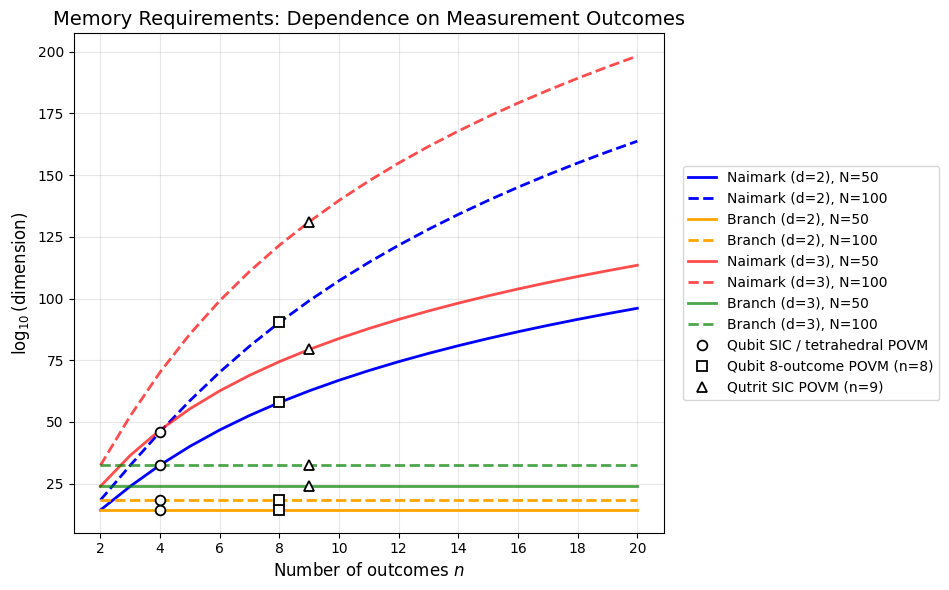

In [20]:
#Figura 1, d=2,3
plt.figure(figsize=(8,6))

# Naimark
plt.plot(
    n_values,
    naimark50,
    color="blue",
    linewidth=2,
    label="Naimark (d=2), N=50"
)

plt.plot(
    n_values,
    naimark100,
    color="blue",
    linestyle="--",
    linewidth=2,
    label="Naimark (d=2), N=100"
)

# Branch
plt.plot(
    n_values,
    branch50,
    color="orange",
    linewidth=2,
    label="Branch (d=2), N=50"
)

plt.plot(
    n_values,
    branch100,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Branch (d=2), N=100"
)

plt.plot(
    n_values,
    naimark50_d3,
    color="red",
    linewidth=2,
    alpha=0.7,
    label="Naimark (d=3), N=50"
)

plt.plot(
    n_values,
    naimark100_d3,
    color="red",
    linestyle="--",
    linewidth=2,
    alpha=0.7,
    label="Naimark (d=3), N=100"
)

plt.plot(
    n_values,
    branch50_d3,
    color="green",
    linewidth=2,
    alpha=0.7,
    label="Branch (d=3), N=50"
)

plt.plot(
    n_values,
    branch100_d3,
    color="green",
    linestyle="--",
    linewidth=2,
    alpha=0.7,
    label="Branch (d=3), N=100"
)

# n = 4 
for y in [
    log_memory_naimark(50, 2, 4),
    log_memory_naimark(100, 2, 4),
    log_memory_branch(50, 2),
    log_memory_branch(100, 2),
]:
    plt.plot(4,y, marker="o", markersize=7, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.3,
             linestyle="None",zorder=10)
    
# n = 8 
for y in [
    log_memory_naimark(50, 2, 8),
    log_memory_naimark(100, 2, 8),
    log_memory_branch(50, 2),
    log_memory_branch(100, 2),
]:
    plt.plot(8, y, marker="s",markersize=7, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.3,
             linestyle="None")
#n=9
for y in [
    log_memory_naimark(100, 3, 9),
    log_memory_naimark(50, 3, 9),
    log_memory_branch(50, 3),
    log_memory_branch(100, 3),
]:
    plt.plot(9, y, marker="^",markersize=7, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.3,
             linestyle="None",zorder=10)

# Labels
plt.xticks(np.arange(2, 21, 2))
plt.xlabel("Number of outcomes $n$", fontsize=12)
plt.ylabel(r"$\log_{10}(\mathrm{dimension})$", fontsize=12)
plt.title("Memory Requirements: Dependence on Measurement Outcomes", fontsize=14)

# Grid and legend
plt.grid(True, alpha=0.3)
plt.plot(
    [], [],
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="None",
    label="Qubit SIC / tetrahedral POVM"
)

plt.plot(
    [], [],
    marker="s",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="None",
    label="Qubit 8-outcome POVM (n=8)"
)
plt.plot(
    [], [],
    marker="^",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="None",
    label="Qutrit SIC POVM (n=9)"
)
plt.legend(
    fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout(rect=[0,0,1.2,1])
plt.show()

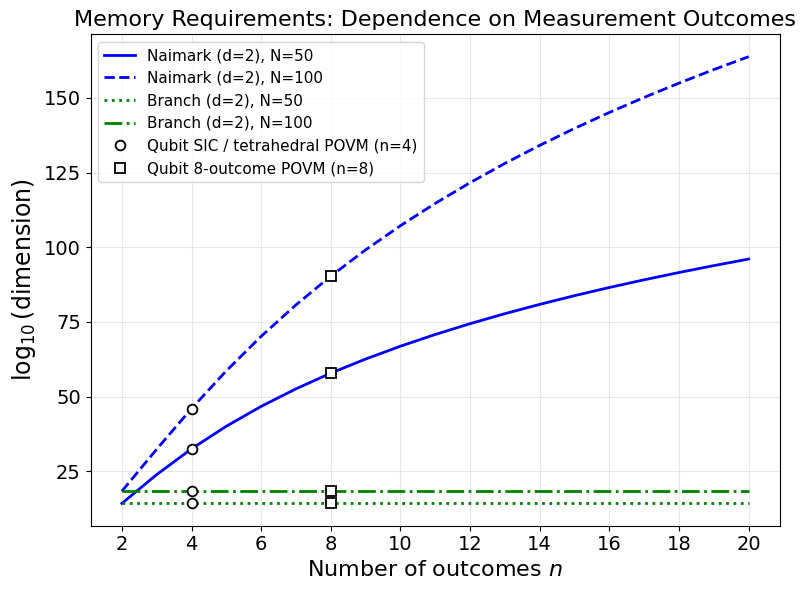

In [21]:
#Figura 1, d=2
plt.figure(figsize=(8,6))

# Naimark
plt.plot(
    n_values,
    naimark50,
    color="blue",
    linewidth=2,
    label="Naimark (d=2), N=50"
)

plt.plot(
    n_values,
    naimark100,
    color="blue",
    linestyle="--",
    linewidth=2,
    label="Naimark (d=2), N=100"
)

# Branch
plt.plot(
    n_values,
    branch50,
    color="green",
    linestyle=":",
    linewidth=2,
    label="Branch (d=2), N=50"
)

plt.plot(
    n_values,
    branch100,
    color="green",
    linestyle="-.",
    linewidth=2,
    label="Branch (d=2), N=100"
)

# n = 4 
for y in [
    log_memory_naimark(50, 2, 4),
    log_memory_naimark(100, 2, 4),
    log_memory_branch(50, 2),
    log_memory_branch(100, 2)
]:
    plt.plot(4,y, marker="o", markersize=7, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.3,
             linestyle="None")
    
# n = 8 
for y in [
    log_memory_naimark(50, 2, 8),
    log_memory_naimark(100, 2, 8),
    log_memory_branch(50, 2),
    log_memory_branch(100, 2)
]:
    plt.plot(8, y, marker="s",markersize=7, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.3,
             linestyle="None")

plt.xticks(np.arange(2, 21, 2),fontsize=14)
plt.yticks(np.arange(25, 200, 25),fontsize=14)
plt.xlabel(r"Number of outcomes $n$", fontsize=16)
plt.ylabel(r"$\log_{10}(\mathrm{dimension})$", fontsize=17)
plt.title(r"Memory Requirements: Dependence on Measurement Outcomes", fontsize=16)

plt.grid(True, alpha=0.3)
plt.plot(
    [], [],
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="None",
    label="Qubit SIC / tetrahedral POVM (n=4)"
)

plt.plot(
    [], [],
    marker="s",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="None",
    label="Qubit 8-outcome POVM (n=8)"
)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("fig_memory_vs_outcomes_d=2.pdf",bbox_inches="tight")
plt.show()

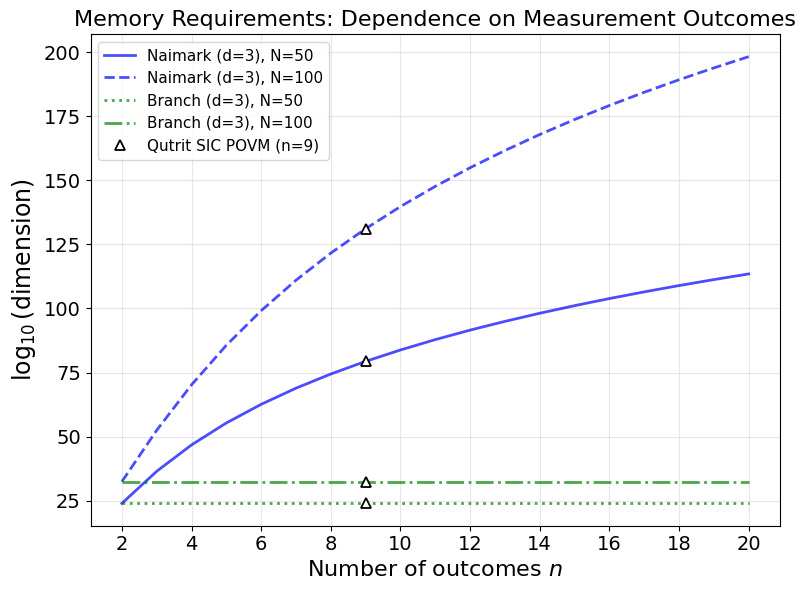

In [22]:
plt.figure(figsize=(8,6))

plt.plot(
    n_values,
    naimark50_d3,
    color="blue",
    linewidth=2,
    alpha=0.7,
    label="Naimark (d=3), N=50"
)

plt.plot(
    n_values,
    naimark100_d3,
    color="blue",
    linestyle="--",
    linewidth=2,
    alpha=0.7,
    label="Naimark (d=3), N=100"
)

plt.plot(
    n_values,
    branch50_d3,
    color="green",
    linestyle=":",
    linewidth=2,
    alpha=0.7,
    label="Branch (d=3), N=50"
)

plt.plot(
    n_values,
    branch100_d3,
    color="green",
    linestyle="-.",
    linewidth=2,
    alpha=0.7,
    label="Branch (d=3), N=100"
)

for y in [
    log_memory_naimark(100, 3, 9),
    log_memory_naimark(50, 3, 9),
    log_memory_branch(50, 3),
    log_memory_branch(100, 3),
]:
    plt.plot(9, y, marker="^",markersize=7, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.3,
             linestyle="None",zorder=10)

# Labels
plt.xticks(np.arange(2, 21, 2),fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("Number of outcomes $n$", fontsize=16)
plt.ylabel(r"$\log_{10}(\mathrm{dimension})$", fontsize=17)
plt.title("Memory Requirements: Dependence on Measurement Outcomes", fontsize=16)

# Grid and legend
plt.grid(True, alpha=0.3)

plt.plot(
    [], [],
    marker="^",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="None",
    label="Qutrit SIC POVM (n=9)"
)
plt.legend(fontsize=11)

plt.tight_layout()
#plt.savefig("fig_memory_vs_outcomes_d=3.png", dpi=300, bbox_inches="tight")
plt.savefig("fig_memory_vs_outcomes_d=3.pdf",bbox_inches="tight")
plt.show()

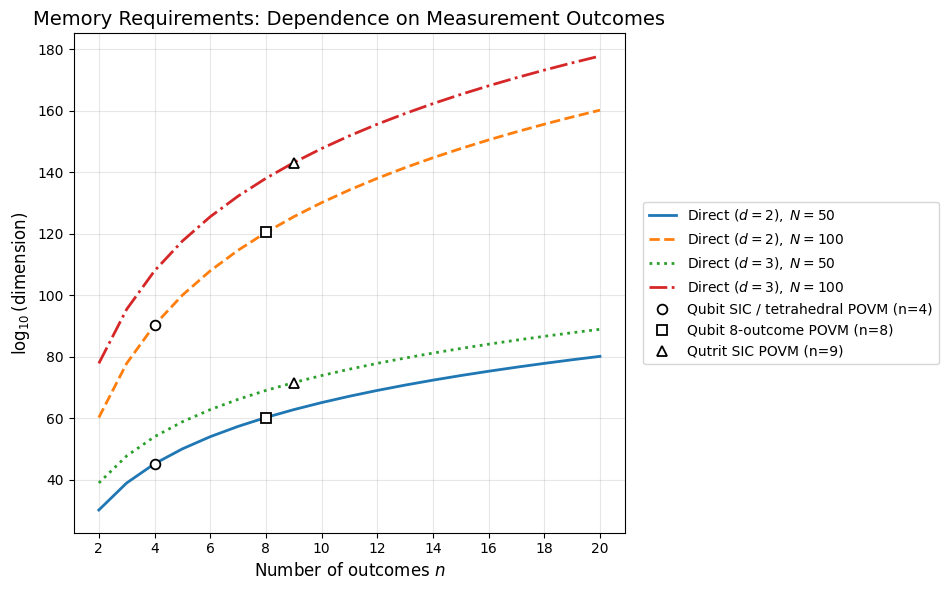

In [23]:
n_values = np.arange(2, 21)

direct_d2_N50 = [log_memory_direct(50, 2, n) for n in n_values]
direct_d2_N100 = [log_memory_direct(100, 2, n) for n in n_values]

direct_d3_N50 = [log_memory_direct(50, 3, n) for n in n_values]
direct_d3_N100 = [log_memory_direct(100, 3, n) for n in n_values]

plt.figure(figsize=(8,6))

plt.plot(
    n_values,
    direct_d2_N50,
    linewidth=2,
    linestyle="-",
    label=r"Direct ($d=2),\;N=50$"
)

plt.plot(
    n_values,
    direct_d2_N100,
    linewidth=2,
    linestyle="--",
    label=r"Direct ($d=2),\;N=100$"
)

plt.plot(
    n_values,
    direct_d3_N50,
    linewidth=2,
    linestyle=":",
    label=r"Direct $(d=3),\;N=50$"
)

plt.plot(
    n_values,
    direct_d3_N100,
    linewidth=2,
    linestyle="-.",
    label=r"Direct $(d=3),\;N=100$"
)

for y in [
    log_memory_direct(100, 3, 9),
    log_memory_direct(50, 3, 9)
]:
    plt.plot(9, y, marker="^",markersize=7, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.3,
             linestyle="None",zorder=10)

for y in [
    log_memory_direct(50, 2, 4),
    log_memory_direct(100, 2, 4)
]:
    plt.plot(4,y, marker="o", markersize=7, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.3,
             linestyle="None")
    
# n = 8 
for y in [
    log_memory_direct(50, 2, 8),
    log_memory_direct(100, 2, 8)
]:
    plt.plot(8, y, marker="s",markersize=7, markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.3,
             linestyle="None")
    
plt.xticks(np.arange(2, 21, 2))
plt.xlabel("Number of outcomes $n$", fontsize=12)
plt.ylabel(r"$\log_{10}(\mathrm{dimension})$", fontsize=12)
plt.title("Memory Requirements: Dependence on Measurement Outcomes", fontsize=14)

plt.grid(True, alpha=0.3)

plt.plot(
    [], [],
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="None",
    label="Qubit SIC / tetrahedral POVM (n=4)"
)

plt.plot(
    [], [],
    marker="s",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="None",
    label="Qubit 8-outcome POVM (n=8)"
)

plt.plot(
    [], [],
    marker="^",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="None",
    label="Qutrit SIC POVM (n=9)"
)

plt.legend(
    fontsize=10,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout(rect=[0,0,1.2,1])

plt.savefig("fig_direct_memory_vs_outcomes.pdf", bbox_inches="tight")
# plt.savefig("fig_direct_memory_vs_outcomes.png", dpi=300, bbox_inches="tight")

plt.show()

In [24]:
N_values = np.arange(1, 501)

success_naimark_values = [
    success_naimark(N, 2, 4)
    for N in N_values
]

success_branch_values = [
    success_branch(N, 2)
    for N in N_values
]

success_direct_values = [
    success_direct(N, 2, 4)
    for N in N_values
]

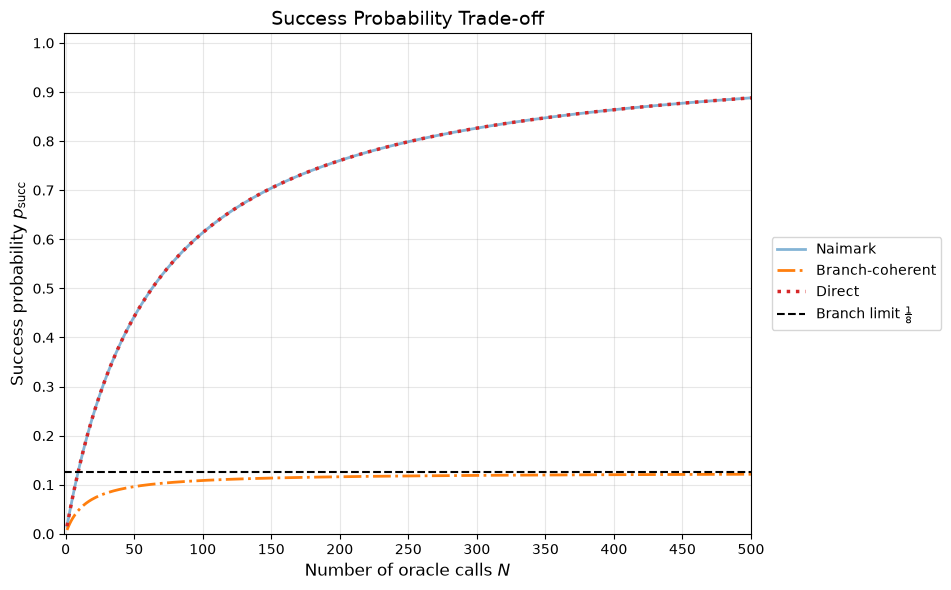

In [404]:
plt.figure(figsize=(8,6))

# Success probabilities
plt.plot(
    N_values,
    success_naimark_values,
    color="tab:blue",
    alpha=0.55,
    linewidth=2,
    label="Naimark"
)

plt.plot(
    N_values,
    success_branch_values,
    color="tab:orange",
    linestyle="-.",
    linewidth=2,
    label="Branch-coherent"
)

plt.plot(
    N_values,
    success_direct_values,
    color="tab:red",
    linestyle=":",
    linewidth=2.5,
    label="Direct"
)

# Asymptote of Branch
plt.axhline(
    y=1/8,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=r"Branch limit $\frac{1}{8}$"
)

# Labels
plt.xticks(np.arange(0, 501, 50))
plt.yticks(np.arange(0, 1.02, 0.1))
plt.xlabel("Number of oracle calls $N$", fontsize=12)
plt.ylabel(r"Success probability $p_{\mathrm{succ}}$", fontsize=12)
plt.title("Success Probability Trade-off", fontsize=14)

# Axes
plt.xlim(-1, 500)
plt.ylim(0, 1.02)

# Grid
plt.grid(True, alpha=0.3)

# Legend
plt.legend( fontsize=10,loc="center left",bbox_to_anchor=(1.02, 0.5))

plt.tight_layout(rect=[0,0,1.2,1])
#plt.savefig("fig_success_vs_N.png",dpi=300,bbox_inches="tight")
plt.savefig("fig_success_vs_N.pdf",bbox_inches="tight")

plt.show() 

In [25]:
N_values = np.arange(1, 501)

direct4_x = [success_direct(N, 2, 4) for N in N_values]
direct4_y = [log_memory_direct(N, 2, 4) for N in N_values]

branch_x = [success_branch(N, 2) for N in N_values]
branch_y = [log_memory_branch(N, 2) for N in N_values]

naimark4_x = [success_naimark(N, 2, 4) for N in N_values]
naimark4_y = [log_memory_naimark(N, 2, 4)for N in N_values]


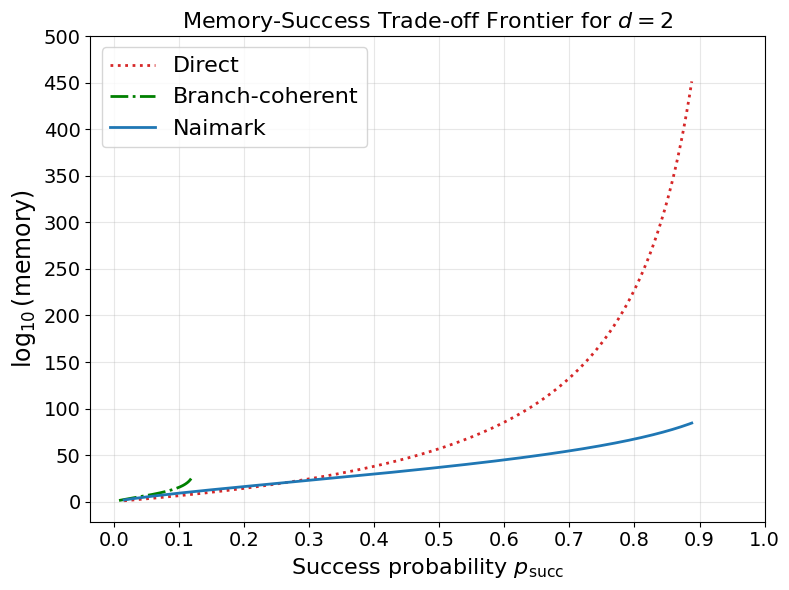

In [26]:
plt.figure(figsize=(8,6))

# Direct
plt.plot(direct4_x, direct4_y,color="tab:red", linestyle=":",linewidth=2,label="Direct")

# Branch
plt.plot(branch_x,branch_y,color="green",linestyle="-.",linewidth=2,label="Branch-coherent")

# Naimark
plt.plot(naimark4_x,naimark4_y,color="tab:blue",linewidth=2, label="Naimark")
#plt.plot(naimark8_x,naimark8_y,color="tab:blue", linestyle="--",linewidth=2,label="Naimark (qubit 8-outcome)")

plt.xticks(np.arange(0, 1.02, 0.1),fontsize=14)
plt.yticks(np.arange(0,501, 50), fontsize=14)
plt.xlabel(r"Success probability $p_{\mathrm{succ}}$", fontsize=16)
plt.ylabel(r"$\log_{10}(\mathrm{memory})$", fontsize=17)
plt.title(r"Memory-Success Trade-off Frontier for $d=2$", fontsize=16)

plt.grid(True, alpha=0.3)

plt.legend(fontsize=16,loc="upper left")
plt.tight_layout()

#plt.savefig("fig_tradeoff_frontier_d2.png", dpi=300, bbox_inches="tight")
plt.savefig("fig_tradeoff_frontier_d2.pdf", bbox_inches="tight")

plt.show()

In [27]:
N_values = np.arange(1, 501)

direct3_x = [success_direct(N, 3, 9) for N in N_values]
direct3_y = [log_memory_direct(N, 3, 9) for N in N_values]

branch3_x = [success_branch(N, 3) for N in N_values]
branch3_y = [log_memory_branch(N, 3) for N in N_values]

naimark3_x = [success_naimark(N, 3, 9) for N in N_values]
naimark3_y = [ log_memory_naimark(N, 3, 9)for N in N_values]

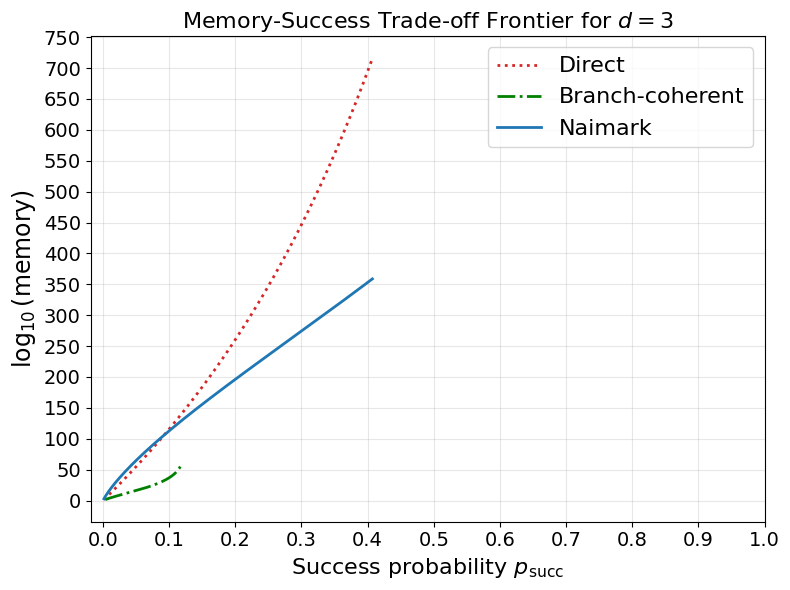

In [28]:
plt.figure(figsize=(8,6))

# Direct
plt.plot(direct3_x, direct3_y,color="tab:red",linestyle=":",linewidth=2,label="Direct")

# Branch
plt.plot(branch3_x,branch3_y,color="green",linestyle="-.",linewidth=2,label="Branch-coherent")

# Naimark
plt.plot(naimark3_x,naimark3_y,color="tab:blue",linewidth=2,label="Naimark")

plt.xticks(np.arange(0, 1.02, 0.1),fontsize=14)
plt.yticks(np.arange(0, 751, 50), fontsize=14)
plt.xlabel(r"Success probability $p_{\mathrm{succ}}$", fontsize=16)
plt.ylabel(r"$\log_{10}(\mathrm{memory})$", fontsize=17)
plt.title(r"Memory-Success Trade-off Frontier for $d=3$", fontsize=16)

plt.grid(True, alpha=0.3)
plt.legend(fontsize=16)
plt.tight_layout()

plt.show()